In [1]:
%pip install yfinance

  Using cached yfinance-1.8.0-py3-none-any.whl.metadata (6.8 kB)
  Using cached beautifulsoup4-4.15.0-py3-none-any.whl.metadata (3.8 kB)
  Using cached curl_cffi-0.17.0-cp310-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (18 kB)
  Using cached lxml-6.1.3-cp314-cp314-manylinux_2_26_x86_64.manylinux_2_28_x86_64.whl.metadata (3.3 kB)
  Using cached peewee-4.5.3-py3-none-any.whl.metadata (10 kB)
  Using cached pytz-2026.6-py2.py3-none-any.whl.metadata (22 kB)
  Using cached websockets-17.4-cp314-cp314-manylinux1_x86_64.manylinux_2_28_x86_64.manylinux_2_5_x86_64.whl.metadata (6.3 kB)
  Using cached cffi-2.1.1-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (2.5 kB)
  Using cached pycparser-3.12-py3-none-any.whl.metadata (9.7 kB)
Using cached yfinance-1.8.0-py3-none-any.whl (158 kB)
Using cached beautifulsoup4-4.15.0-py3-none-any.whl (109 kB)
Using cached curl_cffi-0.17.0-cp310-abi3-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (14.1 MB)
Using cached cffi-

In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

I0000 00:00:1794836459.387960    4251 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794836459.701224    4251 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794836462.678386    4251 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
def baixar_dados_acao(ticker, inicio, fim):
    dados = yf.download(ticker, start=inicio, end=fim)
    return dados
ticker_bb = 'BBAS3.SA'
dados_banco_brasil = baixar_dados_acao(ticker_bb, '2022-01-01', '2025-12-31')
display(dados_banco_brasil.head())

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,BBAS3.SA,BBAS3.SA,BBAS3.SA,BBAS3.SA,BBAS3.SA
Date,,,,,
2022-01-03,10.165298,10.496851,10.158243,10.274640,32338600
2022-01-04,10.175879,10.281694,10.094755,10.271113,23429600
2022-01-05,10.006577,10.221734,9.946616,10.165300,26325600
2022-01-06,10.087703,10.179409,9.946616,10.024214,20271000
2022-01-07,10.098285,10.165301,10.017160,10.091231,16377400


In [4]:
def preparar_dados_regressao(dados, janela=5):
  df = dados[['Close']].copy()
  for i in range(1, janela + 1):
    df[f'fechamento_atraso_{i}'] = df['Close'].shift(i)
  df.dropna(inplace=True)
  X = df.drop(columns=['Close'])
  y = df['Close']
  return X, y

caracteristicas, alvo = preparar_dados_regressao(dados_banco_brasil)

#divisão entre treino(80%) e teste (20%)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    caracteristicas, alvo, test_size=0.2, shuffle=False
)

#nomalização
padronizador = StandardScaler()
X_treino_escalonado = padronizador.fit_transform(X_treino)
X_teste_escalonado = padronizador.transform(X_teste)

/tmp/ipykernel_4251/952928016.py:4: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  df[f'fechamento_atraso_{i}'] = df['Close'].shift(i)
/tmp/ipykernel_4251/952928016.py:5: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace=True)


In [5]:
modelo_tf = Sequential([
    Dense(100, activation='relu', input_dim=X_treino_escalonado.shape[1]),
    Dense(50, activation='relu'),
    Dense(1) # camada de saída para regressão
])

modelo_tf.compile(optimizer='adam', loss='mse')

/home/marcos/repos/Neural-Networks/venv/lib/python3.14/site-packages/keras/src/layers/core/dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1794836467.384261    4251 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [6]:
historico = modelo_tf.fit(
    X_treino_escalonado, y_treino,
    epochs=100,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 337.9062 - val_loss: 453.6820
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 246.2271 - val_loss: 243.9906
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 114.9578 - val_loss: 37.6735
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 48.7163 - val_loss: 38.9100
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 41.1399 - val_loss: 26.7045
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 36.4994 - val_loss: 24.3220
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 31.0298 - val_loss: 21.6284
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 24.9826 - val_loss: 16.7803
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 19.1834 - val_loss: 12.5925
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 14.0434 - val_loss: 8.4789
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 9.9583 - val_loss: 5.6475
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━

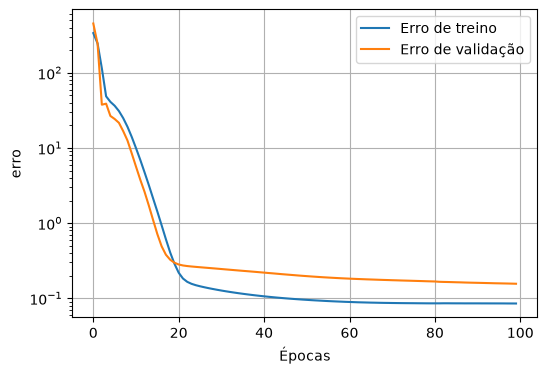

In [7]:
plt.figure(figsize=(6,4))
plt.plot(historico.history['loss'], label='Erro de treino')
plt.plot(historico.history['val_loss'], label='Erro de validação')
plt.xlabel('Épocas')
plt.ylabel('erro')
plt.yscale('log')
plt.grid(True)
plt.legend()
plt.show()

In [8]:
predicoes = modelo_tf.predict(X_teste_escalonado).flatten()

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


In [9]:
erro_medio_absoluto = mean_absolute_error(y_teste, predicoes)
erro_quadratico_medio = mean_squared_error(y_teste, predicoes)
coeficiente_r2 = r2_score(y_teste, predicoes)

print(f"Métricas de Regressão:")
print(f"MAE:{erro_medio_absoluto:.2f}")
print(f"MSE: {erro_quadratico_medio:.2f}")
print(f"R² Score: {coeficiente_r2:.4f}")

Métricas de Regressão:
MAE:0.35
MSE: 0.31
R² Score: 0.9581


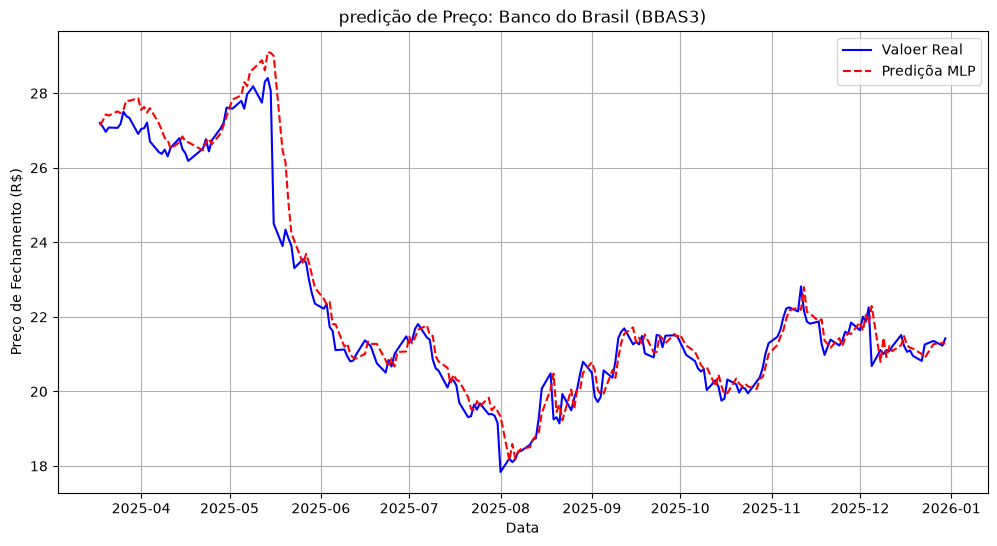

In [10]:
plt.figure(figsize=(12, 6))
plt.plot(y_teste.index, y_teste.values, label='Valoer Real', color='blue')
plt.plot(y_teste.index, predicoes, label='Prediçõa MLP', color='red', linestyle='--')
plt.title('predição de Preço: Banco do Brasil (BBAS3)')
plt.xlabel('Data')
plt.ylabel('Preço de Fechamento (R$)')
plt.legend()
plt.grid(True)
plt.show()